In [1]:
%pip install pandas numpy matplotlib seaborn

   ---------------------------------------- 0.0/9.8 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.8 MB 5.0 MB/s eta 0:00:02
   --- ------------------------------------ 0.8/9.8 MB 2.9 MB/s eta 0:00:04
   ----- ---------------------------------- 1.3/9.8 MB 2.9 MB/s eta 0:00:03
   -------- ------------------------------- 2.1/9.8 MB 2.7 MB/s eta 0:00:03
   ---------- ----------------------------- 2.6/9.8 MB 2.8 MB/s eta 0:00:03
   ------------- -------------------------- 3.4/9.8 MB 2.8 MB/s eta 0:00:03
   ------------------ --------------------- 4.5/9.8 MB 3.0 MB/s eta 0:00:02
   --------------------- ------------------ 5.2/9.8 MB 3.2 MB/s eta 0:00:02
   ------------------------ --------------- 6.0/9.8 MB 3.3 MB/s eta 0:00:02
   ---------------------------- ----------- 7.1/9.8 MB 3.4 MB/s eta 0:00:01
   -------------------------------- ------- 7.9/9.8 MB 3.4 MB/s eta 0:00:01
   ------------------------------------ --- 8.9/9.8 MB 3.5 MB/s eta 0:00:01
   ----------------


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("amazon_sales_dataset.csv")

print("Ukuran data:", df.shape)
print("\nLima data pertama:")
display(df.head())

print("\nInformasi dataset:")
df.info()

Ukuran data: (50000, 13)

Lima data pertama:


,order_id,order_date,product_id,product_category,price,discount_percent,quantity_sold,customer_region,payment_method,rating,review_count,discounted_price,total_revenue
0,1,2022-04-13,2637,Books,128.75,10,4,North America,UPI,3.5,443,115.88,463.52
1,2,2023-03-12,2300,Fashion,302.60,20,5,Asia,Credit Card,3.7,475,242.08,1210.40
2,3,2022-09-28,3670,Sports,495.80,20,2,Europe,UPI,4.4,183,396.64,793.28
3,4,2022-04-17,2522,Books,371.95,15,4,Middle East,UPI,5.0,212,316.16,1264.64
4,5,2022-03-13,1717,Beauty,201.68,0,4,Middle East,UPI,4.6,308,201.68,806.72



Informasi dataset:
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          50000 non-null  int64  
 1   order_date        50000 non-null  str    
 2   product_id        50000 non-null  int64  
 3   product_category  50000 non-null  str    
 4   price             50000 non-null  float64
 5   discount_percent  50000 non-null  int64  
 6   quantity_sold     50000 non-null  int64  
 7   customer_region   50000 non-null  str    
 8   payment_method    50000 non-null  str    
 9   rating            50000 non-null  float64
 10  review_count      50000 non-null  int64  
 11  discounted_price  50000 non-null  float64
 12  total_revenue     50000 non-null  float64
dtypes: float64(4), int64(5), str(4)
memory usage: 5.0 MB


In [3]:
if len(df) < 1000:
    raise ValueError("Dataset memiliki kurang dari 1000 baris.")

data = df.head(1000).copy()

print("Jumlah baris:", len(data))
print("Jumlah kolom:", len(data.columns))

Jumlah baris: 1000
Jumlah kolom: 13


In [4]:
data.isnull().sum()

order_id            0
order_date          0
product_id          0
product_category    0
price               0
discount_percent    0
quantity_sold       0
customer_region     0
payment_method      0
rating              0
review_count        0
discounted_price    0
total_revenue       0
dtype: int64

In [5]:
print("Total sel kosong:", data.isnull().sum().sum())

print("\nKolom yang memiliki data kosong:")
display(data.isnull().sum()[data.isnull().sum() > 0])

Total sel kosong: 0

Kolom yang memiliki data kosong:


Series([], dtype: int64)

In [6]:
print("Jumlah baris duplikat:", data.duplicated().sum())

Jumlah baris duplikat: 0


In [7]:
kolom_numerik = data.select_dtypes(include=np.number).columns

hasil_outlier = []

for kolom in kolom_numerik:
    Q1 = data[kolom].quantile(0.25)
    Q3 = data[kolom].quantile(0.75)
    IQR = Q3 - Q1

    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    jumlah = (
        (data[kolom] < batas_bawah) |
        (data[kolom] > batas_atas)
    ).sum()

    hasil_outlier.append({
        "Kolom": kolom,
        "Batas Bawah": batas_bawah,
        "Batas Atas": batas_atas,
        "Jumlah Outlier": jumlah
    })

tabel_outlier = pd.DataFrame(hasil_outlier)
display(tabel_outlier)

,Kolom,Batas Bawah,Batas Atas,Jumlah Outlier
0,order_id,-498.5000,1499.5000,0
1,product_id,-938.6250,6812.3750,0
2,price,-247.0225,729.9975,0
3,discount_percent,-17.5000,42.5000,0
4,quantity_sold,-1.0000,7.0000,0
5,rating,-1.2500,7.1500,0
6,review_count,-275.5000,760.5000,0
7,discounted_price,-214.9625,628.1175,0
8,total_revenue,-842.2900,2019.3900,12


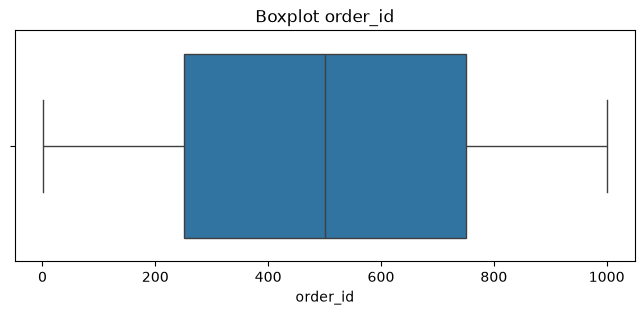

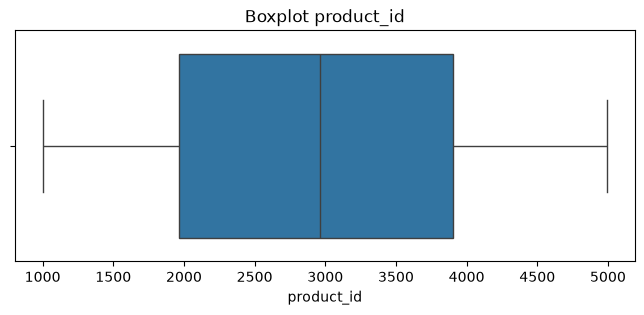

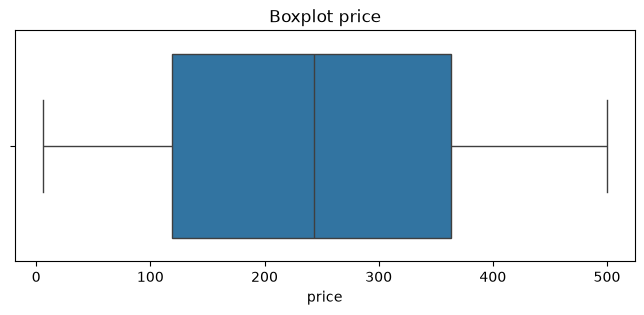

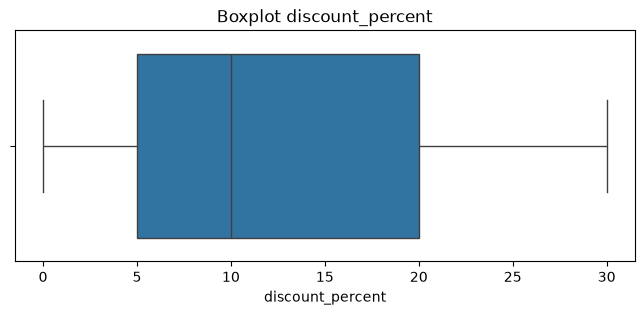

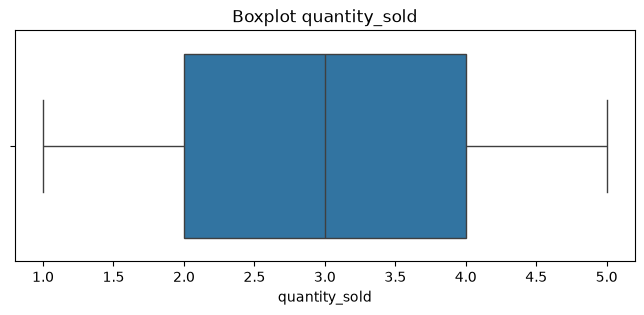

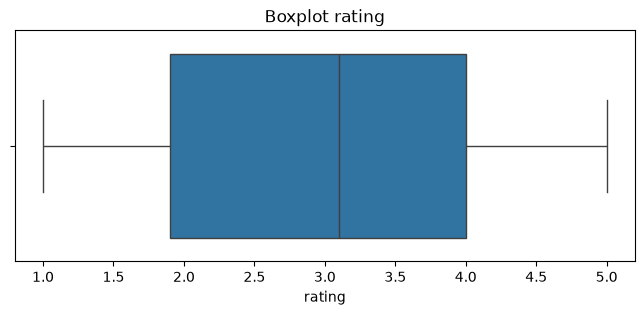

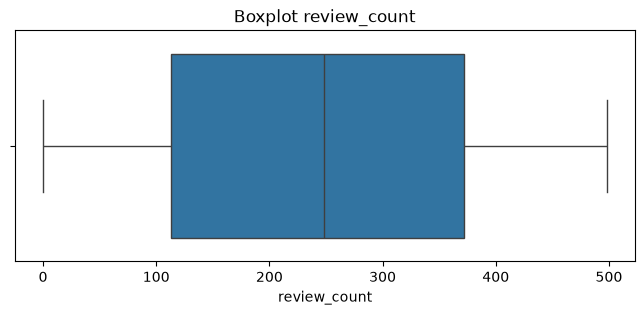

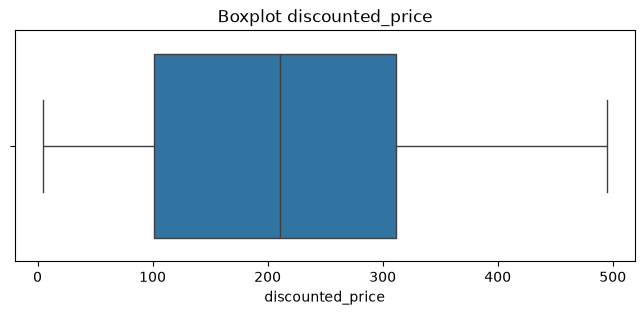

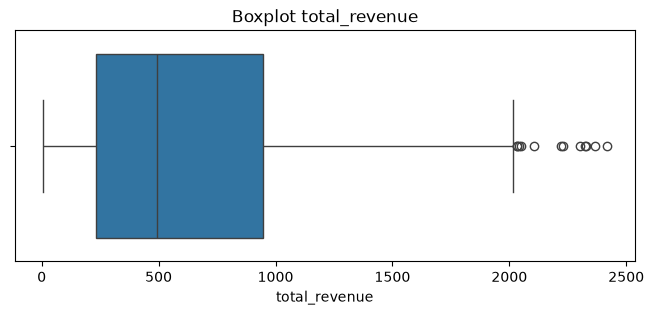

In [8]:
kolom_plot = [
    kolom for kolom in kolom_numerik
    if data[kolom].nunique() > 1
]

for kolom in kolom_plot:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=data[kolom])
    plt.title(f"Boxplot {kolom}")
    plt.show()

In [9]:
for kolom in data.columns:
    if data[kolom].isnull().any():
        if pd.api.types.is_numeric_dtype(data[kolom]):
            median = data[kolom].median()
            data[kolom] = data[kolom].fillna(median)
        else:
            modus = data[kolom].mode(dropna=True)

            if not modus.empty:
                data[kolom] = data[kolom].fillna(modus.iloc[0])

print("Sisa data kosong:", data.isnull().sum().sum())
print("Sisa data duplikat:", data.duplicated().sum())
print("Jumlah baris akhir:", len(data))

data.to_csv("amazon_sales_bersih.csv", index=False)
print("Data bersih berhasil disimpan.")

Sisa data kosong: 0
Sisa data duplikat: 0
Jumlah baris akhir: 1000
Data bersih berhasil disimpan.


In [ ]:
# Membagi rating produk menjadi beberapa kategori
data['kategori_rating'] = pd.cut(
    data['rating'],
    bins=[0, 2, 3, 4, 5],
    labels=['Rendah', 'Sedang', 'Tinggi', 'Sangat Tinggi'],
    include_lowest=True
)

# Menghitung jumlah data setiap kategori
data_kategori = data['kategori_rating'].value_counts()

# Membuat pie chart
plt.figure(figsize=(7, 7))
plt.pie(
    data_kategori,
    labels=data_kategori.index,
    autopct='%1.1f%%',
    startangle=90
)
plt.title('Distribusi Kategori Rating Produk')
plt.show()

# Regresi Logistik, Ridge, dan Lasso

Bagian ini menerapkan tiga metode regresi pada data penjualan Amazon yang sudah dibersihkan (`data`, 1.000 baris).

| No | Metode | Jenis masalah | Fungsi loss | Contoh pada dataset ini |
|----|--------|---------------|-------------|--------------------------|
| 4 | Regresi Logistik | Klasifikasi (biner) | Log-loss | Memprediksi apakah rating produk tinggi (`rating >= 4`) atau tidak |
| 5 | Regresi Ridge | Regresi + regularisasi L2 | SSE + λ Σβ² | Memprediksi `total_revenue` dengan fitur yang saling berkorelasi |
| 6 | Regresi Lasso | Regresi + regularisasi L1 | SSE + λ Σ\|β\| | Memilih fitur paling berpengaruh terhadap `total_revenue` |

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression, RidgeCV, LassoCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             mean_absolute_error, mean_squared_error, r2_score)

# Fitur numerik + kategorikal (one-hot encoding)
fitur_numerik = ['price', 'discount_percent', 'quantity_sold', 'review_count', 'rating', 'discounted_price']
fitur_kategorikal = ['product_category', 'customer_region', 'payment_method']

X_all = pd.concat(
    [data[fitur_numerik],
     pd.get_dummies(data[fitur_kategorikal], drop_first=True, dtype=float)],
    axis=1
)
print("Jumlah fitur:", X_all.shape[1])
X_all.head()

## 4. Regresi Logistik

**Konsep.** Regresi logistik dipakai untuk memprediksi *probabilitas* suatu kejadian yang bersifat kategorik (umumnya biner: Ya/Tidak). Model menghitung kombinasi linear fitur, lalu mengubahnya menjadi probabilitas antara 0 dan 1 dengan fungsi sigmoid:

$$P(Y=1)=\frac{1}{1+e^{-z}},\qquad z=\beta_0+\beta_1x_1+\dots+\beta_px_p$$

Jika $P(Y=1)\ge 0{,}5$ maka kelas diprediksi 1 (Ya), selain itu kelas 0 (Tidak).

**Contoh pada dataset.** Target `rating_tinggi` = 1 jika `rating >= 4`, selain itu 0. Fitur: harga, diskon, jumlah terjual, jumlah ulasan, wilayah, metode pembayaran, dan kategori produk. Kolom `rating` tidak dipakai sebagai fitur karena merupakan dasar pembentuk target (menghindari *data leakage*).

In [ ]:
# Target biner
y_log = (data['rating'] >= 4.0).astype(int)
print("Distribusi kelas:\n", y_log.value_counts())

X_log = X_all.drop(columns=['rating'])
Xtr, Xte, ytr, yte = train_test_split(
    X_log, y_log, test_size=0.2, random_state=42, stratify=y_log
)

scaler_log = StandardScaler().fit(Xtr)
Xtr_s, Xte_s = scaler_log.transform(Xtr), scaler_log.transform(Xte)

logreg = LogisticRegression(max_iter=1000, random_state=42)
logreg.fit(Xtr_s, ytr)

y_pred = logreg.predict(Xte_s)
y_proba = logreg.predict_proba(Xte_s)[:, 1]

hasil_log = pd.DataFrame({
    'Metrik': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Nilai': [accuracy_score(yte, y_pred),
              precision_score(yte, y_pred, zero_division=0),
              recall_score(yte, y_pred, zero_division=0),
              f1_score(yte, y_pred, zero_division=0)]
})
display(hasil_log.round(4))

In [ ]:
# Confusion matrix + kurva sigmoid
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

ConfusionMatrixDisplay(confusion_matrix(yte, y_pred),
                       display_labels=['Rating < 4', 'Rating >= 4']).plot(ax=ax[0], colorbar=False)
ax[0].set_title('Confusion Matrix - Regresi Logistik')

z = logreg.decision_function(Xte_s)
urut = np.argsort(z)
ax[1].scatter(z, yte, alpha=0.3, label='Data aktual (0/1)')
ax[1].plot(z[urut], y_proba[urut], color='orange', lw=2, label='P(Y=1) (sigmoid)')
ax[1].axhline(0.5, color='gray', ls='--', lw=1)
ax[1].set_xlabel('z = β0 + β1x1 + ... + βpxp')
ax[1].set_ylabel('P(Y=1)')
ax[1].set_title('Kurva Sigmoid')
ax[1].legend()
plt.tight_layout()
plt.show()

# Koefisien terbesar (fitur sudah distandardisasi)
koef_log = pd.Series(logreg.coef_[0], index=X_log.columns).sort_values(key=abs, ascending=False)
print("Lima fitur dengan |koefisien| terbesar:")
display(koef_log.head(5).round(4))

## 5. Regresi Ridge

**Konsep.** Regresi Ridge adalah regresi linear dengan regularisasi **L2**. Fungsi loss ditambah penalti berupa jumlah kuadrat koefisien:

$$\text{Loss}=\text{SSE}+\lambda\sum_{j=1}^{p}\beta_j^{2}$$

Semakin besar $\lambda$ (`alpha` di scikit-learn), semakin kecil koefisien. Ridge mengurangi *overfitting* dan stabil saat fitur saling berkorelasi (multikolinearitas), namun koefisien hanya menyusut mendekati nol, tidak menjadi nol.

**Contoh pada dataset.** Memprediksi `total_revenue`. Fitur `price`, `discount_percent`, dan `discounted_price` saling berkaitan erat (harga diskon dihitung dari harga dan diskon), sehingga cocok untuk menunjukkan manfaat Ridge dibanding regresi linear biasa.

In [ ]:
# Cek multikolinearitas
print("Korelasi price vs discounted_price:", round(data['price'].corr(data['discounted_price']), 4))

y_reg = data['total_revenue']
X_reg = X_all.copy()
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

scaler_reg = StandardScaler().fit(Xr_tr)
Xr_tr_s, Xr_te_s = scaler_reg.transform(Xr_tr), scaler_reg.transform(Xr_te)

def evaluasi(nama, model):
    p = model.predict(Xr_te_s)
    mse = mean_squared_error(yr_te, p)
    return {'Model': nama, 'MAE': mean_absolute_error(yr_te, p),
            'MSE': mse, 'RMSE': np.sqrt(mse), 'R2': r2_score(yr_te, p)}

lin = LinearRegression().fit(Xr_tr_s, yr_tr)
ridge = RidgeCV(alphas=np.logspace(-3, 3, 50), cv=5).fit(Xr_tr_s, yr_tr)
print("Alpha terbaik Ridge:", round(ridge.alpha_, 4))

hasil_ridge = pd.DataFrame([evaluasi('Linear Regression', lin), evaluasi('Ridge', ridge)])
display(hasil_ridge.round(4))

In [ ]:
# Perbandingan koefisien: Linear vs Ridge (6 fitur numerik)
nama = list(X_reg.columns)
idx = [nama.index(k) for k in fitur_numerik]
bandingkan = pd.DataFrame({
    'Linear': lin.coef_[idx],
    'Ridge': ridge.coef_[idx]
}, index=fitur_numerik)
display(bandingkan.round(4))

bandingkan.plot(kind='bar', figsize=(9, 4))
plt.title('Koefisien Linear vs Ridge (data terstandardisasi)')
plt.ylabel('Koefisien')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

## 6. Regresi Lasso

**Konsep.** Regresi Lasso adalah regresi linear dengan regularisasi **L1**:

$$\text{Loss}=\text{SSE}+\lambda\sum_{j=1}^{p}|\beta_j|$$

Penalti L1 dapat membuat sebagian koefisien menjadi tepat **nol**, sehingga Lasso sekaligus berfungsi sebagai seleksi fitur otomatis.

**Contoh pada dataset.** Dari seluruh fitur (numerik + hasil one-hot), Lasso memilih fitur yang paling berpengaruh terhadap `total_revenue`. Fitur dengan koefisien nol dianggap tidak relevan.

In [ ]:
lasso = LassoCV(alphas=np.logspace(-3, 2, 100), cv=5, random_state=42, max_iter=20000).fit(Xr_tr_s, yr_tr)
print("Alpha terbaik Lasso:", round(lasso.alpha_, 4))

hasil_lasso = pd.DataFrame([evaluasi('Linear Regression', lin),
                            evaluasi('Ridge', ridge),
                            evaluasi('Lasso', lasso)])
display(hasil_lasso.round(4))

koef_lasso = pd.Series(lasso.coef_, index=X_reg.columns)
terpilih = koef_lasso[koef_lasso != 0].sort_values(key=abs, ascending=False)
print(f"Fitur terpilih: {len(terpilih)} dari {len(koef_lasso)}")
print(f"Fitur dibuang (koefisien = 0): {(koef_lasso == 0).sum()}")
display(terpilih.round(4).to_frame('Koefisien Lasso'))

In [ ]:
# Visualisasi: 10 koefisien terbesar Lasso + jalur regularisasi
from sklearn.linear_model import lasso_path

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

top = koef_lasso.reindex(koef_lasso.abs().sort_values(ascending=False).index).head(10)
top.sort_values().plot(kind='barh', ax=ax[0], color='teal')
ax[0].set_title('10 Koefisien Terbesar - Lasso')
ax[0].set_xlabel('Koefisien')

alphas_path, coefs_path, _ = lasso_path(Xr_tr_s, yr_tr, alphas=np.logspace(-3, 2, 60))
for k in range(coefs_path.shape[0]):
    ax[1].plot(np.log10(alphas_path), coefs_path[k], lw=1)
ax[1].axvline(np.log10(lasso.alpha_), color='black', ls='--', label='alpha terbaik')
ax[1].set_xlabel('log10(alpha)')
ax[1].set_ylabel('Koefisien')
ax[1].set_title('Jalur Regularisasi Lasso')
ax[1].legend()
plt.tight_layout()
plt.show()

## Ringkasan Perbandingan

| Aspek | Regresi Logistik | Regresi Ridge | Regresi Lasso |
|-------|------------------|---------------|---------------|
| Tujuan | Klasifikasi biner | Prediksi nilai numerik | Prediksi nilai numerik + seleksi fitur |
| Penalti | - (opsional L2) | L2 (Σβ²) | L1 (Σ\|β\|) |
| Koefisien menjadi nol | Tidak | Tidak (hanya menyusut) | Ya |
| Metrik evaluasi | Accuracy, Precision, Recall, F1 | MAE, MSE, RMSE, R² | MAE, MSE, RMSE, R² |
| Kelebihan | Hasil berupa probabilitas | Stabil saat multikolinearitas | Model lebih sederhana |